# AR Prediction System – Exploratory Data Analysis (EDA)

## Task 2

Objective: Analyze invoice amounts, payment delays, customer behaviour,
payment trends and outstanding receivables.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns

In [16]:
df = pd.read_csv("../Task_1_Data_Cleaning/cleaned_AR_dataset.csv")

In [17]:
df

,invoice_id,invoice_number,invoice_date,due_date,customer_id,customer_name,customer_email,customer_city,customer_state,customer_country,...,currency,payment_method,payment_status,payment_date,order_channel,sales_rep,is_overdue,days_to_pay,payment_delay,paid_late
0,2500001,INV-002500001,2025-12-01,2025-12-16,CUST-033946,James Chen,james.chen33946@example.com,Singapore,Singapore,Singapore,...,USD,UPI,Paid,2025-12-05,Online Portal,Rohan Iyer,0,4,-11,False
1,2500002,INV-002500002,2025-01-04,2025-02-03,CUST-037116,Diya Sharma,diya.sharma37116@example.com,Manchester,England,UK,...,INR,Bank Transfer,Paid,2025-01-25,Marketplace,Karen Kumar,0,21,-9,False
2,2500003,INV-002500003,2025-07-07,2025-08-06,CUST-027731,Reyansh Nair,reyansh.nair27731@example.com,London,England,UK,...,GBP,UPI,Paid,2025-07-21,Phone Order,Richard Miller,0,14,-16,False
3,2500004,INV-002500004,2025-02-17,2025-03-19,CUST-047646,Arjun Singh,arjun.singh47646@example.com,San Francisco,California,USA,...,EUR,Credit Card,Paid,2025-03-11,Walk-in,Krishna Sharma,0,22,-8,False
4,2500005,INV-002500005,2024-05-09,2024-05-24,CUST-015519,Thomas Wang,thomas.wang15519@example.com,Seattle,Washington,USA,...,INR,Bank Transfer,Overdue,2024-05-24,Sales Rep,Rohan Nair,1,15,0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1999995,4499996,INV-004499996,2024-09-14,2024-11-13,CUST-012695,Susan Liu,susan.liu12695@example.com,Houston,Texas,USA,...,EUR,UPI,Paid,2024-10-15,Online Portal,William Rodriguez,0,31,-29,False
1999996,4499997,INV-004499997,2025-07-17,2025-09-15,CUST-054903,Linda Reddy,linda.reddy54903@example.com,Tokyo,Tokyo,Japan,...,INR,Digital Wallet,Paid,2025-08-23,Online Portal,Susan Iyer,0,37,-23,False
1999997,4499998,INV-004499998,2025-02-06,2025-04-07,CUST-024764,Vivaan Chen,vivaan.chen24764@example.com,Bengaluru,Karnataka,India,...,INR,Debit Card,Paid,2025-03-27,Email,Elizabeth Brown,0,49,-11,False
1999998,4499999,INV-004499999,2024-11-28,2024-12-13,CUST-011635,Ananya Watanabe,ananya.watanabe11635@example.com,Boston,Massachusetts,USA,...,EUR,Debit Card,Paid,2024-12-12,Online Portal,Vihaan Verma,0,14,-1,False


In [19]:
df.columns

Index(['invoice_id', 'invoice_number', 'invoice_date', 'due_date',
       'customer_id', 'customer_name', 'customer_email', 'customer_city',
       'customer_state', 'customer_country', 'vendor_id', 'vendor_name',
       'product_id', 'product_category', 'product_name', 'quantity',
       'unit_price', 'discount_percent', 'tax_percent', 'subtotal',
       'discount_amount', 'tax_amount', 'shipping_cost', 'total_amount',
       'currency', 'payment_method', 'payment_status', 'payment_date',
       'order_channel', 'sales_rep', 'is_overdue', 'days_to_pay',
       'payment_delay', 'paid_late'],
      dtype='str')

In [21]:
df["invoice_date"] = pd.to_datetime(df["invoice_date"])

In [23]:
df["due_date"] = pd.to_datetime(df["due_date"])

In [24]:
df["payment_date"] = pd.to_datetime(df["payment_date"])

In [26]:
df.dtypes

invoice_id                   int64
invoice_number                 str
invoice_date        datetime64[us]
due_date            datetime64[us]
customer_id                    str
customer_name                  str
customer_email                 str
customer_city                  str
customer_state                 str
customer_country               str
vendor_id                      str
vendor_name                    str
product_id                     str
product_category               str
product_name                   str
quantity                     int64
unit_price                 float64
discount_percent           float64
tax_percent                float64
subtotal                   float64
discount_amount            float64
tax_amount                 float64
shipping_cost              float64
total_amount               float64
currency                       str
payment_method                 str
payment_status                 str
payment_date        datetime64[us]
order_channel       

In [27]:
df["total_amount"].describe()

count    2.000000e+06
mean     3.397916e+04
std      2.989939e+04
min      4.710000e+00
25%      9.485370e+03
50%      2.535221e+04
75%      5.149472e+04
max      1.599360e+05
Name: total_amount, dtype: float64

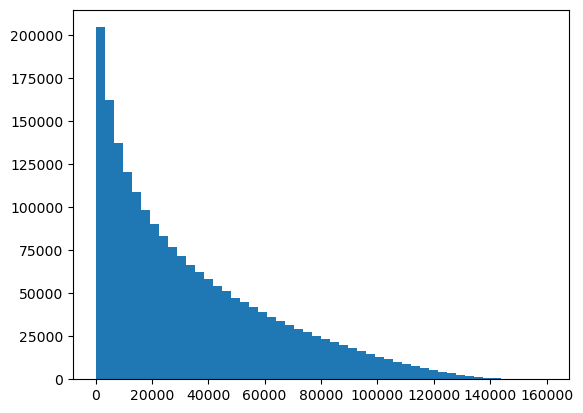

In [31]:
plt.hist(df["total_amount"] , bins = 50);

In [32]:
import seaborn as sns

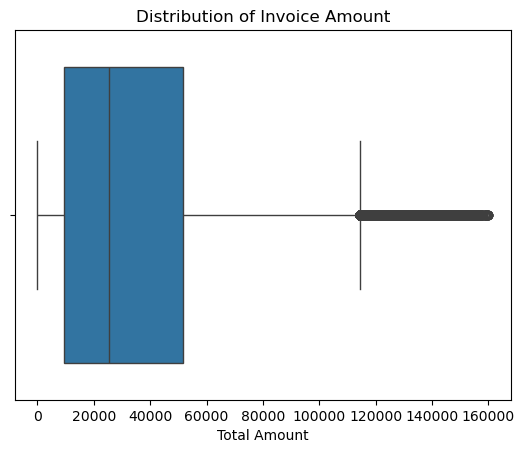

In [33]:
sns.boxplot(data=df, x="total_amount")
plt.title("Distribution of Invoice Amount")
plt.xlabel("Total Amount")
plt.show()

In [34]:
df["days_to_pay"].describe()

count    2.000000e+06
mean     1.981419e+01
std      1.463195e+01
min      0.000000e+00
25%      9.000000e+00
50%      1.500000e+01
75%      3.000000e+01
max      6.000000e+01
Name: days_to_pay, dtype: float64

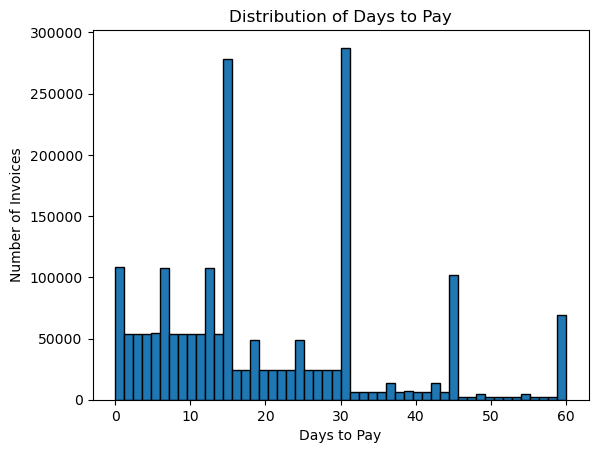

In [35]:
plt.hist(df["days_to_pay"], bins=50, edgecolor="black")
plt.title("Distribution of Days to Pay")
plt.xlabel("Days to Pay")
plt.ylabel("Number of Invoices")
plt.show()

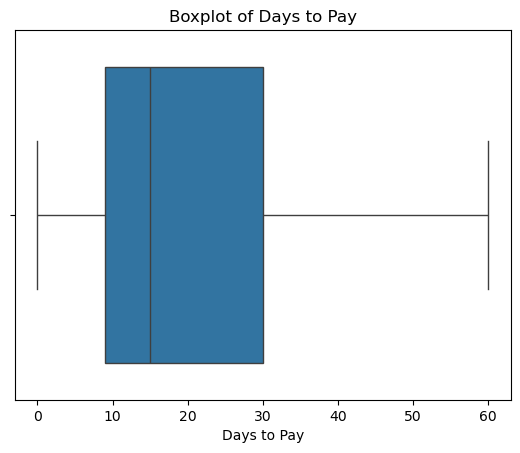

In [36]:
sns.boxplot(data=df, x="days_to_pay")
plt.title("Boxplot of Days to Pay")
plt.xlabel("Days to Pay")
plt.show()

In [37]:
df["days_to_pay"].quantile([0.25, 0.50, 0.75])

0.25     9.0
0.50    15.0
0.75    30.0
Name: days_to_pay, dtype: float64

In [38]:
df["payment_delay"].describe()

count    2.000000e+06
mean    -1.020384e+01
std      1.223221e+01
min     -6.000000e+01
25%     -1.500000e+01
50%     -6.000000e+00
75%      0.000000e+00
max      0.000000e+00
Name: payment_delay, dtype: float64

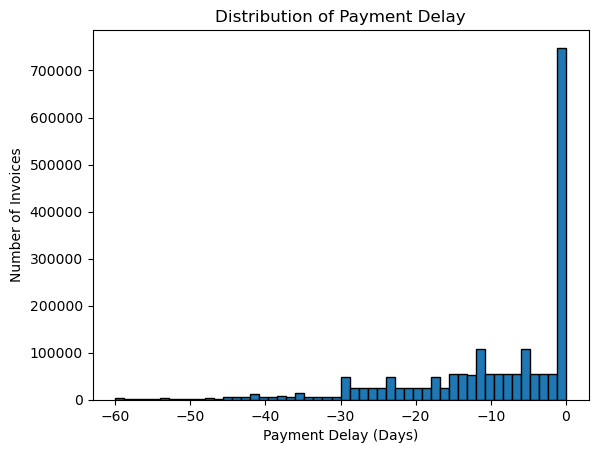

In [39]:
plt.hist(df["payment_delay"], bins=50, edgecolor="black")
plt.title("Distribution of Payment Delay")
plt.xlabel("Payment Delay (Days)")
plt.ylabel("Number of Invoices")
plt.show()

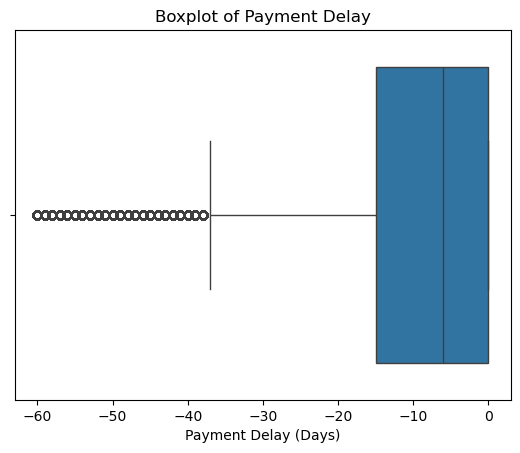

In [40]:
sns.boxplot(x=df["payment_delay"])
plt.title("Boxplot of Payment Delay")
plt.xlabel("Payment Delay (Days)")
plt.show()

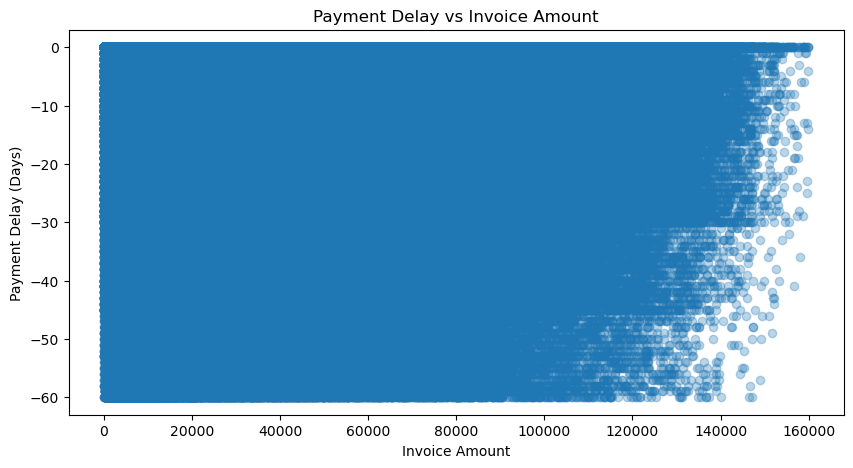

In [41]:
plt.figure(figsize=(10, 5))

plt.scatter(df["total_amount"], df["payment_delay"], alpha=0.3)

plt.title("Payment Delay vs Invoice Amount")
plt.xlabel("Invoice Amount")
plt.ylabel("Payment Delay (Days)")

plt.show()

In [42]:
df["total_amount"].corr(df["payment_delay"])

np.float64(-0.0007201863075006098)

In [43]:
country_delay = df.groupby("customer_country")["payment_delay"].mean().sort_values()

display(country_delay)

customer_country
Singapore   -10.261623
UK          -10.227390
USA         -10.211014
India       -10.202807
Germany     -10.199745
UAE         -10.192005
Canada      -10.185381
Japan       -10.171480
Australia   -10.160294
Name: payment_delay, dtype: float64

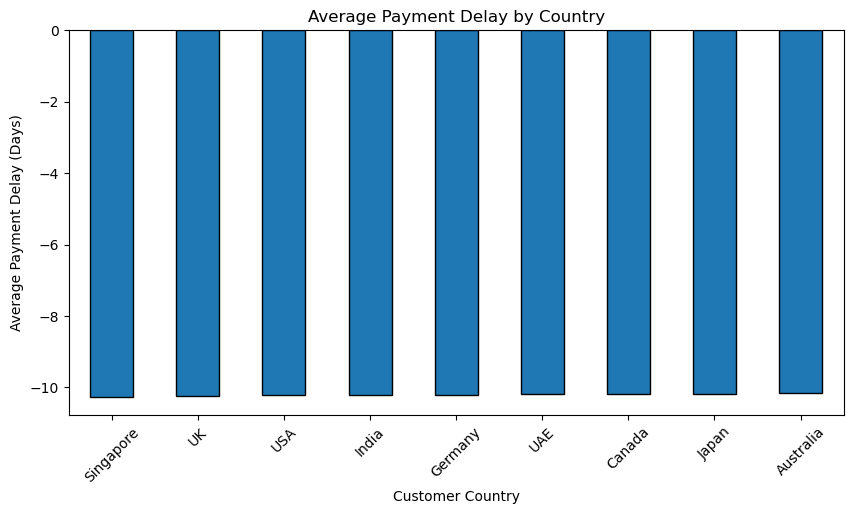

In [44]:
plt.figure(figsize=(10, 5))

country_delay.plot(kind="bar", edgecolor="black")

plt.title("Average Payment Delay by Country")
plt.xlabel("Customer Country")
plt.ylabel("Average Payment Delay (Days)")
plt.xticks(rotation=45)

plt.show()

In [46]:
df.columns

Index(['invoice_id', 'invoice_number', 'invoice_date', 'due_date',
       'customer_id', 'customer_name', 'customer_email', 'customer_city',
       'customer_state', 'customer_country', 'vendor_id', 'vendor_name',
       'product_id', 'product_category', 'product_name', 'quantity',
       'unit_price', 'discount_percent', 'tax_percent', 'subtotal',
       'discount_amount', 'tax_amount', 'shipping_cost', 'total_amount',
       'currency', 'payment_method', 'payment_status', 'payment_date',
       'order_channel', 'sales_rep', 'is_overdue', 'days_to_pay',
       'payment_delay', 'paid_late'],
      dtype='str')

In [48]:
customer_delay = df.groupby("customer_name")["payment_delay"].mean().sort_values(ascending=False)

customer_delay

customer_name
William Johnson    -9.022651
Rohan Liu          -9.064145
Meera Martinez     -9.193387
Joseph Park        -9.195305
Aarav Li           -9.213380
                     ...    
Li Reddy          -11.253705
Meera Wang        -11.261582
Robert Davis      -11.292881
Charles Iyer      -11.391980
Chen Jones        -11.442771
Name: payment_delay, Length: 1500, dtype: float64

In [49]:
country_delay = df.groupby("customer_country")["payment_delay"].mean().sort_values(ascending=False)

country_delay

customer_country
Australia   -10.160294
Japan       -10.171480
Canada      -10.185381
UAE         -10.192005
Germany     -10.199745
India       -10.202807
USA         -10.211014
UK          -10.227390
Singapore   -10.261623
Name: payment_delay, dtype: float64

In [50]:
df["invoice_month"] = df["invoice_date"].dt.month

monthly_delay = df.groupby("invoice_month")["payment_delay"].mean()

monthly_delay

invoice_month
1    -10.176970
2    -10.196387
3    -10.225277
4    -10.258742
5    -10.204592
6    -10.181877
7    -10.170480
8    -10.176863
9    -10.215558
10   -10.247624
11   -10.181601
12   -10.210427
Name: payment_delay, dtype: float64

In [51]:
df["invoice_weekday"] = df["invoice_date"].dt.day_name()

weekday_delay = df.groupby("invoice_weekday")["payment_delay"].mean()

weekday_delay

invoice_weekday
Friday      -10.209160
Monday      -10.248290
Saturday    -10.170242
Sunday      -10.161125
Thursday    -10.216643
Tuesday     -10.228014
Wednesday   -10.192752
Name: payment_delay, dtype: float64

In [53]:
monthly_volume = df.groupby(df["invoice_date"].dt.month).size()

monthly_volume

invoice_date
1     169633
2     155784
3     169800
4     163522
5     169977
6     164369
7     169803
8     169730
9     163970
10    169826
11    163760
12    169826
dtype: int64

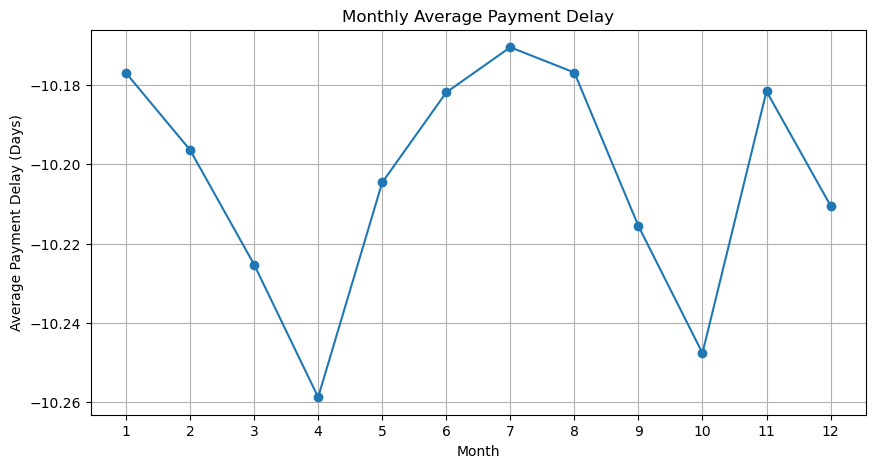

In [58]:
monthly_delay.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Average Payment Delay")
plt.xlabel("Month")
plt.ylabel("Average Payment Delay (Days)")
plt.xticks(range(1, 13))
plt.grid()
plt.show()

In [59]:
df["invoice_day"] = df["invoice_date"].dt.day

month_end = df[df["invoice_day"] >= 25]

month_end.shape[0]

424021

In [60]:
month_end_delay = df[df["invoice_day"] >= 25]["payment_delay"].mean()
other_days_delay = df[df["invoice_day"] < 25]["payment_delay"].mean()

print("Month-end average delay:", month_end_delay)
print("Other days average delay:", other_days_delay)

Month-end average delay: -10.173647059933351
Other days average delay: -10.211967925968557


In [61]:
df["invoice_quarter"] = df["invoice_date"].dt.quarter

quarter_delay = df.groupby("invoice_quarter")["payment_delay"].mean()

quarter_delay

invoice_quarter
1   -10.199642
2   -10.214878
3   -10.187312
4   -10.213598
Name: payment_delay, dtype: float64

In [63]:
df["paid_late"].value_counts()

paid_late
False    2000000
Name: count, dtype: int64

In [64]:
df["paid_late"].value_counts(normalize=True) * 100

paid_late
False    100.0
Name: proportion, dtype: float64

In [66]:
df["payment_status"].value_counts()

payment_status
Paid         1358819
Pending       341015
Overdue       199777
Cancelled     100389
Name: count, dtype: int64

In [67]:
outstanding = df[df["payment_status"].isin(["Pending", "Overdue"])]

print("Outstanding invoice count:", len(outstanding))
print("Outstanding amount:", outstanding["total_amount"].sum())

Outstanding invoice count: 540792
Outstanding amount: 18380053504.35


In [68]:
overdue = df[df["payment_status"] == "Overdue"]

print("Overdue invoice count:", len(overdue))
print("Overdue invoice amount:", overdue["total_amount"].sum())

Overdue invoice count: 199777
Overdue invoice amount: 6775561121.42


In [69]:
df["invoice_date"].max()

Timestamp('2025-12-31 00:00:00')

In [70]:
outstanding_df = df[df["payment_status"].isin(["Pending", "Overdue"])].copy()

outstanding_df["invoice_age"] = (
    df["invoice_date"].max() - outstanding_df["invoice_date"]
).dt.days

In [71]:
outstanding_df["invoice_age"].describe()

count    540792.000000
mean        364.737648
std         210.968152
min           0.000000
25%         182.000000
50%         364.000000
75%         547.000000
max         730.000000
Name: invoice_age, dtype: float64

In [72]:
bins = [0, 30, 60, 90, float("inf")]
labels = ["0-30", "31-60", "61-90", "90+"]

outstanding_df["aging_bucket"] = pd.cut(
    outstanding_df["invoice_age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [73]:
outstanding_df["aging_bucket"].value_counts().sort_index()

aging_bucket
0-30      22937
31-60     22154
61-90     22161
90+      473540
Name: count, dtype: int64

In [74]:
outstanding_df.groupby("aging_bucket", observed=True)["total_amount"].sum()

aging_bucket
0-30     7.853529e+08
31-60    7.574483e+08
61-90    7.559733e+08
90+      1.608128e+10
Name: total_amount, dtype: float64

In [75]:
outstanding_df["payment_status"].value_counts()

payment_status
Pending    341015
Overdue    199777
Name: count, dtype: int64

In [76]:
outstanding_df.groupby("payment_status")["total_amount"].sum()

payment_status
Overdue    6.775561e+09
Pending    1.160449e+10
Name: total_amount, dtype: float64

In [77]:
df["paid_late"].value_counts()

paid_late
False    2000000
Name: count, dtype: int64

In [78]:
numeric_df = df.select_dtypes(include="number")

numeric_df.columns

Index(['invoice_id', 'quantity', 'unit_price', 'discount_percent',
       'tax_percent', 'subtotal', 'discount_amount', 'tax_amount',
       'shipping_cost', 'total_amount', 'is_overdue', 'days_to_pay',
       'payment_delay', 'invoice_month', 'invoice_day', 'invoice_quarter'],
      dtype='str')

In [80]:
corr = numeric_df.drop(columns=["invoice_id"]).corr()
corr

,quantity,unit_price,discount_percent,tax_percent,subtotal,discount_amount,tax_amount,shipping_cost,total_amount,is_overdue,days_to_pay,payment_delay,invoice_month,invoice_day,invoice_quarter
quantity,1.000000,-0.000785,0.000901,-0.001459,0.649954,0.348325,0.521236,0.001206,0.642157,-0.001810,-0.000162,-0.000898,0.000873,0.000675,0.000755
unit_price,-0.000785,1.000000,-0.000691,0.001123,0.660886,0.353202,0.530701,0.000204,0.653190,0.000581,0.000011,0.000121,0.000147,0.000701,0.000151
discount_percent,0.000901,-0.000691,1.000000,0.000299,-0.000181,0.637208,-0.075043,-0.000391,-0.091942,-0.001046,-0.001094,0.000401,0.000211,-0.001552,0.000297
tax_percent,-0.001459,0.001123,0.000299,1.000000,0.000192,-0.000633,0.442518,0.001469,0.069917,-0.001097,-0.000263,-0.000084,0.000127,0.000527,0.000355
subtotal,0.649954,0.660886,-0.000181,0.000192,1.000000,0.534902,0.802637,0.000782,0.988237,-0.000835,-0.000202,-0.000757,0.000776,0.001102,0.000723
discount_amount,0.348325,0.353202,0.637208,-0.000633,0.534902,1.000000,0.345099,-0.000139,0.425768,-0.001531,-0.001264,-0.000615,0.000390,-0.000075,0.000424
tax_amount,0.521236,0.530701,-0.075043,0.442518,0.802637,0.345099,1.000000,0.000962,0.859768,-0.000788,-0.000260,-0.000599,0.000757,0.001527,0.000832
shipping_cost,0.001206,0.000204,-0.000391,0.001469,0.000782,-0.000139,0.000962,1.000000,0.002560,-0.000435,0.001313,0.000032,-0.000538,0.000907,-0.000713
total_amount,0.642157,0.653190,-0.091942,0.069917,0.988237,0.425768,0.859768,0.002560,1.000000,-0.000708,-0.000068,-0.000720,0.000790,0.001275,0.000748
is_overdue,-0.001810,0.000581,-0.001046,-0.001097,-0.000835,-0.001531,-0.000788,-0.000435,-0.000708,1.000000,0.232399,0.277887,0.000653,-0.000073,0.000763


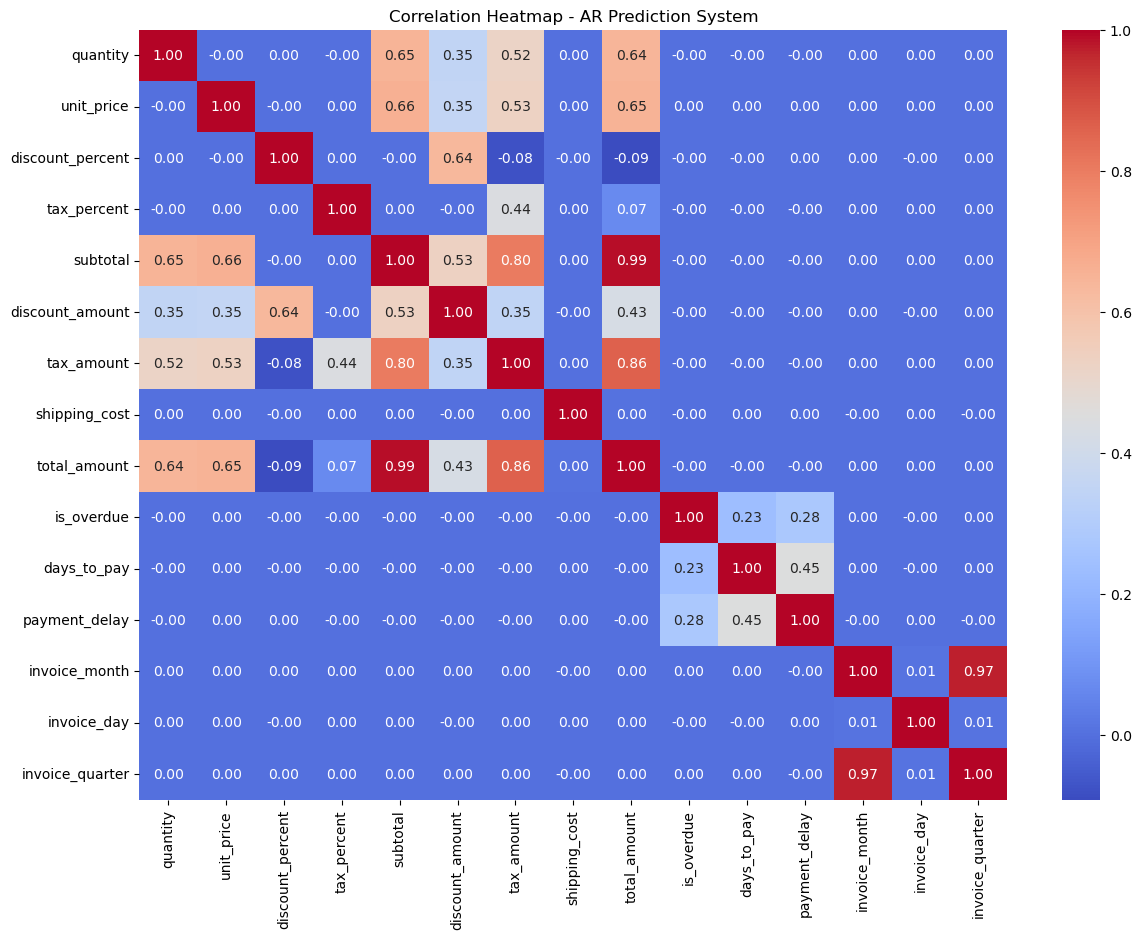

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - AR Prediction System")
plt.show();